# Reading the PLY (Stanford Polygon) format with `pyramids-mesh`

The **PLY** (Polygon File Format, a.k.a. Stanford Triangle Format) is a simple surface format born from 3D scanning: an ASCII or binary header declaring `element vertex`/`element face` blocks, followed by the coordinates and the polygon vertex lists. `pyramids-mesh` reads it straight into a `pyramids.netcdf.ugrid` object, so a scan mesh lands in the same data model as every other driver. This notebook reads a tiny two-triangle PLY, explores its geometry, and shows the GIS tools that then come for free.

## 1. Plotting backend and a figure helper

`pyramids-mesh` draws through **cleopatra** (reached via pyramids), which builds its own matplotlib figure. Under the non-interactive `Agg` backend nothing embeds on its own, so we define a tiny `show()` helper that grabs the current figure and displays it as an inline PNG. Call it right after every plot.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
%matplotlib inline
import matplotlib.pyplot as plt
from IPython.display import Image, display


def show():
    """Render the current matplotlib figure inline as an embedded PNG."""
    from io import BytesIO

    buf = BytesIO()
    plt.gcf().savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close("all")
    buf.seek(0)
    display(Image(data=buf.read()))

## 2. Imports

The import below is all the setup this adds: `UgridDataset` is the object every driver hands back (a `Mesh2d` or `Network1d` wrapper). Importing from `pyramids` also puts its vendored GDAL/PROJ data in place for you, so nothing about it is order-sensitive in a notebook -- just import the names you use.

In [2]:
from pathlib import Path

import numpy as np
from pyramids.netcdf.ugrid import UgridDataset

DATA = Path("../../examples/data")
MESH = DATA / "minimal.ply"
MESH.name, MESH.exists()

('minimal.ply', True)

`minimal.ply` is a loose file at the root of the data directory (not in a sub-folder), so we point `MESH` straight at it. The `(name, True)` tuple confirms the path resolves.

## 3. Read the file in one call

`UgridDataset.read_file` takes the `Path` and an explicit `driver="ply"`. Passing the driver skips suffix sniffing and guarantees the PLY reader is used.

In [3]:
ds = UgridDataset.read_file(MESH, driver="ply")
ds

UgridDataset(mesh='mesh2d', n_node=4, n_face=2, n_edge=0, variables=['node_z'])

The repr shows a `UgridDataset` with a handful of nodes and faces — the whole file parsed into topology in a single call.

## 4. Explore the dataset

A handful of attributes describe what we loaded: node and face counts, the coordinate reference system, the names of any data variables, and the spatial extent.

In [4]:
import pandas as pd
pd.Series({
    "n_node": ds.n_node,
    "n_face": ds.n_face,
    "crs": ds.crs,
    "epsg": ds.epsg,
    "data_variable_names": ds.data_variable_names,
    "bounds": ds.bounds,
}).to_frame("value")

,value
n_node,4
n_face,2
crs,None
epsg,None
data_variable_names,[node_z]
bounds,"(0.0, 0.0, 1.0, 1.0)"


This minimal PLY has **4 nodes and 2 triangular faces**. `crs`/`epsg` are `None`: PLY stores raw coordinates with no projection metadata. A `node_z` variable is present — PLY vertices carry an elevation (the third coordinate), which the reader keeps as node data. The `bounds` give the planar `(xmin, ymin, xmax, ymax)` extent.

## 5. A statistical summary of the fields

`summary()` returns a pandas frame with one row per data variable (count, min, max, mean, std).

In [5]:
ds.summary()

,count,min,max,mean,std
variable,,,,,
node_z,4,2.0,3.5,2.75,0.559017


The single row summarises `node_z`: the per-vertex elevations stored in the file. There are no face fields yet — we attach one next.

## 6. The underlying `Mesh2d` geometry

`ds.mesh` is the `Mesh2d` object carrying the raw topology: node coordinates, the face-node connectivity table of shape `(n_face, k)` (row *i* lists the node indices of cell *i*), per-face areas, and cell centroids.

In [6]:
mesh = ds.mesh
fnc = np.asarray(mesh.face_node_connectivity.data)
areas = np.asarray(mesh.face_areas)
centroids = np.asarray(mesh.face_centroids)  # shape (2, n_face)
pd.Series({
    "connectivity_shape": fnc.shape,
    "nodes_per_face_k": fnc.shape[1],
    "area_min": float(areas.min()),
    "area_max": float(areas.max()),
    "centroids_shape": centroids.shape,
    "mesh_bounds": mesh.bounds,
}).to_frame("value")

,value
connectivity_shape,"(2, 3)"
nodes_per_face_k,3
area_min,0.5
area_max,0.5
centroids_shape,"(2, 2)"
mesh_bounds,"(0.0, 0.0, 1.0, 1.0)"


`k = 3` confirms triangles. Each of the two faces has an area of 0.5 (two unit triangles), and `face_centroids` is `(2, n_face)` — one `(x, y)` column per cell.

## 7. The mesh outline (wireframe)

`plot_outline()` draws the bare cell edges, with no field attached — the quickest look at the raw geometry this driver produced.

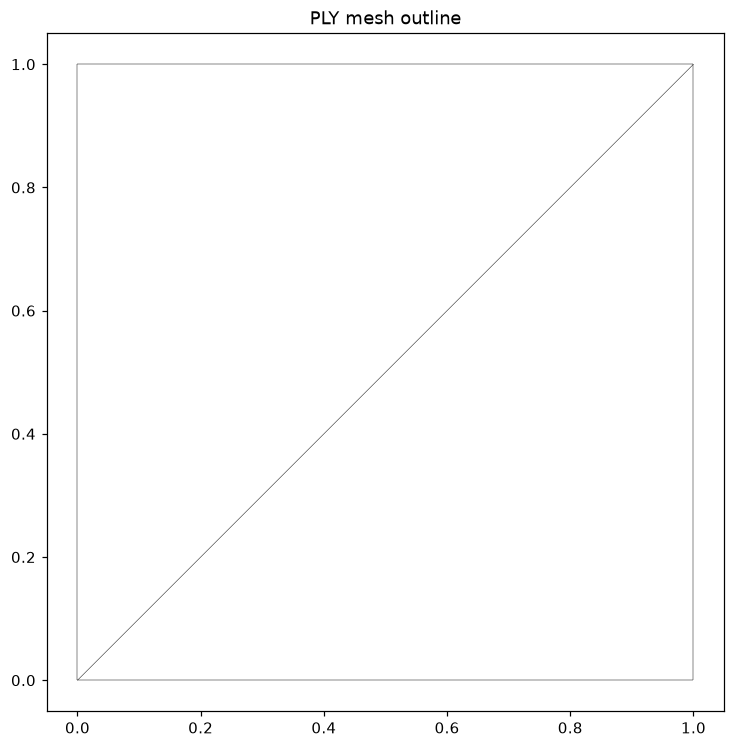

In [7]:
g = ds.plot_outline()
g.ax.set_title("PLY mesh outline")
show()

Two triangles sharing an edge — the entire mesh. PLY is a surface format, so even this trivial example is a valid, closed triangulation.

## 8. A data map: attach and colour by cell area

These surface formats carry no field data, so there is nothing to colour by yet. We attach a derived **`cell_area`** variable at the face location and plot it — turning the geometry into a proper choropleth.

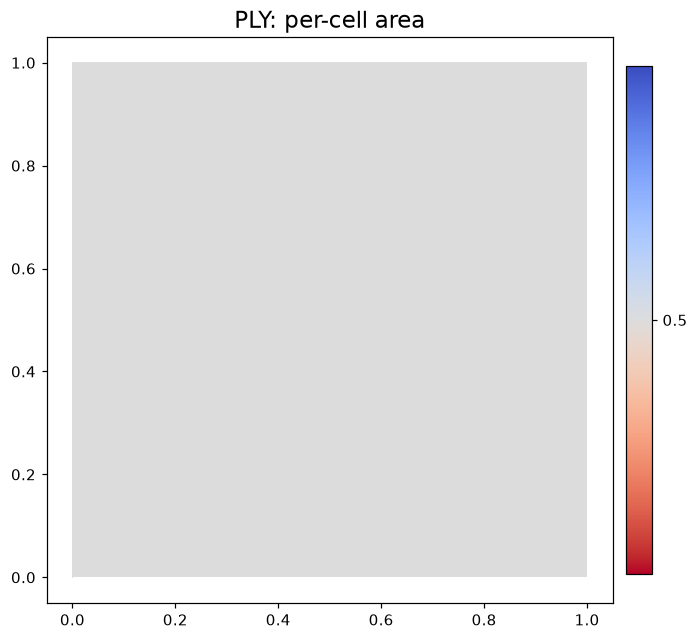

In [8]:
d2 = ds.with_variable("cell_area", np.asarray(mesh.face_areas), location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True,
        title="PLY: per-cell area")
show()

Both cells shade identically because they have equal area — expected for two congruent unit triangles. On a real scan mesh this map would reveal the fine/coarse regions of the triangulation at a glance.

## 9. GIS operations, for free

Because a `UgridDataset` is a first-class pyramids object, a whole GIS toolkit comes along. First, every face as a row in a GeoDataFrame.

In [9]:
gdf = ds.to_geodataframe()
print(gdf.shape, list(gdf.columns))
gdf.head()

(2, 1) ['geometry']


,geometry
0,"POLYGON ((0 0, 1 0, 1 1, 0 0))"
1,"POLYGON ((0 0, 1 1, 0 1, 0 0))"


One row per face, each a shapely polygon in the `geometry` column. Note the GeoDataFrame carries no CRS — matching the `crs=None` we saw above.

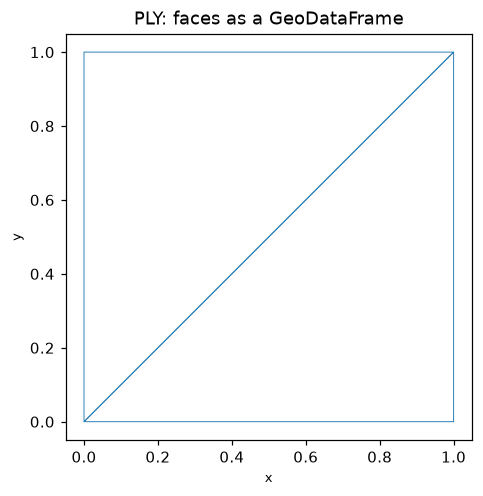

In [10]:
ax = gdf.boundary.plot(color="#1f77b4", linewidth=0.6)
ax.set_title("PLY: faces as a GeoDataFrame")
ax.set_aspect("equal")
show()

The GeoDataFrame is the gateway to the entire shapely/geopandas ecosystem — spatial joins, buffering, reprojection, export to any OGR vector format — all on the mesh cells.

### Bounding polygon

`bounding_polygon()` returns a single shapely geometry: the dissolved outer footprint of the mesh.

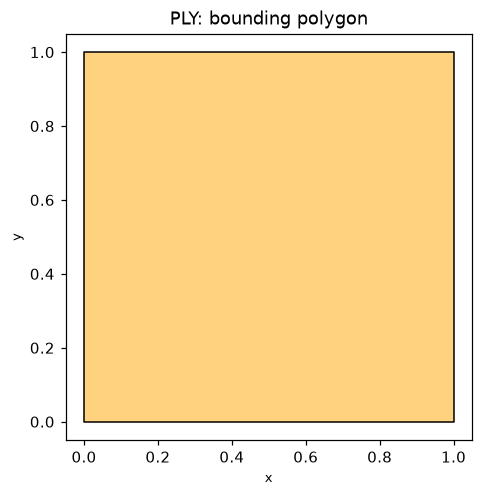

Polygon 1.0


In [11]:
import geopandas as gpd

poly = ds.bounding_polygon()
ax = gpd.GeoSeries([poly]).plot(facecolor="#ffd27f", edgecolor="k")
ax.set_title("PLY: bounding polygon")
ax.set_aspect("equal")
show()
print(type(poly).__name__, round(poly.area, 4))

The footprint is the union of the two triangles: the unit square, area 1.0.

### Derived topology and connectivity

A few more derived quantities are a method call away. `circumcenters()` is defined only for triangular meshes; `exterior_edges()` indexes the boundary edges; `connected_components()` labels disjoint pieces; `sparse_adjacency()` is the face-to-face graph as a sparse matrix.

In [12]:
try:
    cc = np.asarray(ds.circumcenters())
    circ = f"{cc.shape} array"
except ValueError as e:
    circ = f"skipped ({e})"
ext = np.asarray(ds.exterior_edges())
comp = np.asarray(ds.connected_components())
adj = ds.sparse_adjacency()
pd.Series({
    "circumcenters": circ,
    "n_boundary_edges": int(ext.size),
    "n_connected_components": int(np.unique(comp).size),
    "adjacency_shape": adj.shape,
    "adjacency_nnz": int(adj.nnz),
}).to_frame("value")

,value
circumcenters,"(2, 2) array"
n_boundary_edges,4
n_connected_components,1
adjacency_shape,"(2, 2)"
adjacency_nnz,2


Circumcenters are defined (the mesh is triangular), every edge on this tiny two-cell mesh is a boundary edge, and the whole thing is a single connected component.

### Cropping to a bounding box

`crop(bbox=...)` keeps the faces that fall within (or touch) a rectangle, returning a new `UgridDataset`. Here we crop to the left portion of the extent and redraw it.

faces: 2 -> 1


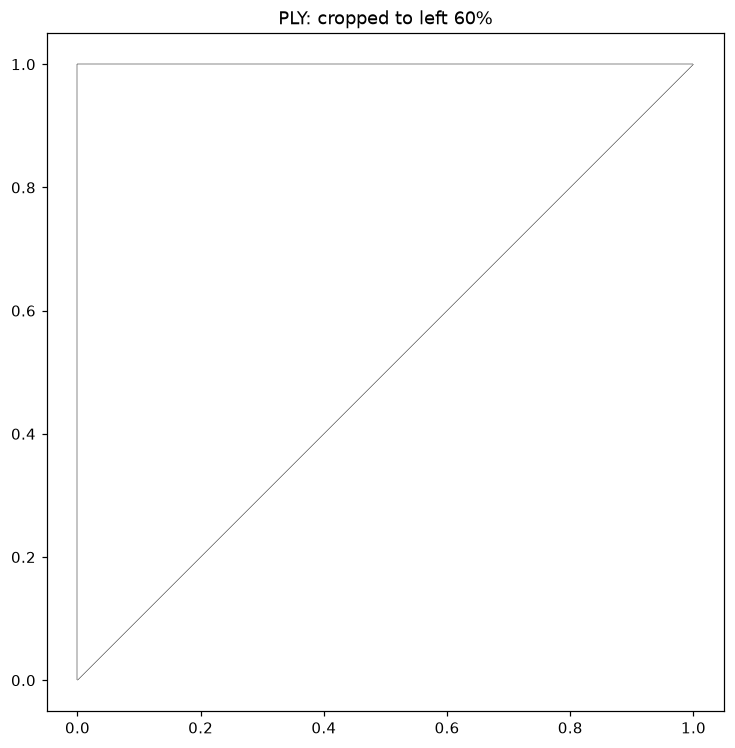

In [13]:
xmin, ymin, xmax, ymax = ds.bounds
bbox = (xmin, ymin, xmin + 0.6 * (xmax - xmin), ymax)
cropped = ds.crop(bbox=bbox)
print(f"faces: {ds.n_face} -> {cropped.n_face}")
gc = cropped.plot_outline()
gc.ax.set_title("PLY: cropped to left 60%")
show()

Cropping to the left 60% of the extent keeps the faces that touch the box. On such a small mesh both triangles straddle the cut, so the cropped mesh still shows the cells that intersect the rectangle.

### Round-tripping and the xarray view

`to_file(..., driver=...)` writes the mesh back out in any writable driver (here the solver-neutral 2DM), and `to_xarray()` exposes the whole dataset as an `xarray.Dataset` for NetCDF-style analysis.

In [14]:
import tempfile

out = Path(tempfile.gettempdir()) / "roundtrip.2dm"
ds.to_file(out, driver="2dm")
xds = ds.to_xarray()
print("wrote", out.name, "bytes:", out.stat().st_size)
print(xds.dims)

wrote roundtrip.2dm bytes: 110
FrozenMappingWarningOnValuesAccess({'mesh2d_scalar': 1, 'mesh2d_nNodes': 4, 'mesh2d_nFaces': 2, 'mesh2d_nMaxFaceNodes': 3})


The mesh survives the round-trip to a different format, and `to_xarray()` hands us a familiar labelled-array object — proof that a format-specific reader produces a fully generic, interoperable dataset.

## 10. What we skip here, and why

- **`to_crs(...)`** needs a source CRS to reproject from, but PLY files carry no georeferencing (`crs=None`), so there is nothing to reproject. Attach a CRS first if the coordinates are known to be in a specific projection.
- **`rasterize_like(...)` / `regrid(...)`** require a *reference grid* (a raster or target mesh) to sample onto; with only this standalone mesh in hand there is no target, so they are out of scope for this tutorial.

## Takeaway

A PLY surface mesh reads in one line into the same `UgridDataset` as every other format. PLY itself contributes only the file parsing — node coordinates, face lists and the `node_z` elevation — and the moment it is a `UgridDataset`, the full pyramids mesh and GIS toolkit (plotting, GeoDataFrame export, bounding polygon, cropping, cross-format write-out) applies unchanged.